# Text Classification from Scratch

##**1. Setup Environment**

In [ ]:
!pip install datasets==3.6.0 -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 491.5/491.5 kB 29.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.6/193.6 kB 14.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 146.7/146.7 kB 11.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2025.3.0 which is incompatible.


In [ ]:
import os
import re
import time
import torch
import string
import random
import numpy as np
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

from collections import Counter
from datasets import load_dataset
from torch.nn import functional as F
from torch.utils.data import DataLoader
from sklearn.metrics import classification_report

In [ ]:
def set_seed(seed_value=42):
    random.seed(seed_value)
    np.random.seed(seed_value)
    torch.manual_seed(seed_value)
    torch.cuda.manual_seed_all(seed_value)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

SEED = 42
set_seed(SEED)

print(f"Random seed set to {SEED}")

Random seed set to 42


##**2. Load Dataset**

In [ ]:
dataset_id = "uitnlp/vietnamese_students_feedback"
ds = load_dataset(dataset_id)


README.md:   0%|          | 0.00/4.79k [00:00<?, ?B/s]

vietnamese_students_feedback.py:   0%|          | 0.00/4.97k [00:00<?, ?B/s]

default/train/0000.parquet: reconstructing file:   0%|          |  0.00B /  475kB            

default/train/0000.parquet: downloading bytes:           |  0.00B            

default/validation/0000.parquet: reconstructing file:   0%|          |  0.00B / 63.3kB            

default/validation/0000.parquet: downloading bytes:           |  0.00B            

default/test/0000.parquet: reconstructing file:   0%|          |  0.00B /  134kB            

default/test/0000.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/11426 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1583 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/3166 [00:00<?, ? examples/s]

In [ ]:
for i in range(10):
  print(ds["train"][i+3])

{'sentence': 'chưa áp dụng công nghệ thông tin và các thiết bị hỗ trợ cho việc giảng dạy .', 'sentiment': 0, 'topic': 0}
{'sentence': 'thầy giảng bài hay , có nhiều bài tập ví dụ ngay trên lớp .', 'sentiment': 2, 'topic': 0}
{'sentence': 'giảng viên đảm bảo thời gian lên lớp , tích cực trả lời câu hỏi của sinh viên , thường xuyên đặt câu hỏi cho sinh viên .', 'sentiment': 2, 'topic': 0}
{'sentence': 'em sẽ nợ môn này , nhưng em sẽ học lại ở các học kỳ kế tiếp .', 'sentiment': 1, 'topic': 3}
{'sentence': 'thời lượng học quá dài , không đảm bảo tiếp thu hiệu quả .', 'sentiment': 0, 'topic': 1}
{'sentence': 'nội dung môn học có phần thiếu trọng tâm , hầu như là chung chung , khái quát khiến sinh viên rất khó nắm được nội dung môn học .', 'sentiment': 0, 'topic': 1}
{'sentence': 'cần nói rõ hơn bằng cách trình bày lên bảng thay vì nhìn vào slide .', 'sentiment': 0, 'topic': 1}
{'sentence': 'thầy rất tận tình và đi dạy rất đúng giờ .', 'sentiment': 2, 'topic': 0}
{'sentence': 'dễ bị áp lực 

##**3. Preprocessing**

### 3.1 Tokenizer & Vocabulary

In [ ]:
def basic_tokenizer(text):
    return text.lower().split()

In [ ]:
class Vocabulary:
    def __init__(self, max_tokens=None, specials=None):
        self.max_tokens = max_tokens
        self.specials = specials if specials else []
        self.stoi = {}
        self.itos = {}
        self.default_index = 0

    def build_vocab(self, sentences, tokenizer):
        counter = Counter()
        for sent in sentences:
            tokens = tokenizer(sent)
            my_lists=counter.update(tokens)

        for idx, token in enumerate(self.specials):
            self.stoi[token] = idx
            self.itos[idx] = token

        keep_common=self.max_tokens-len(self.specials) if self.max_tokens else None
        most_common = counter.most_common(keep_common)
        for idx,token in enumerate(most_common):
            self.stoi[token] = idx + len(self.specials)
            self.itos[idx + len(self.specials)] = token


    def set_default_index(self, index):
        self.default_index = index

    def __call__(self, tokens):
        return [self.stoi.get(token, self.default_index) for token in tokens]

    def __len__(self):
        return len(self.stoi)

    def __getitem__(self, token):
        return self.stoi.get(token, self.default_index)

In [ ]:
vocab_size = 10000
vocabulary = Vocabulary(max_tokens=vocab_size,
                        specials=["<PAD>", "<UNK>"])
vocabulary.build_vocab(ds["train"]["sentence"],
                       tokenizer=basic_tokenizer)
vocabulary.set_default_index(vocabulary["<UNK>"])


### 3.2 Tokenize Dataset

In [ ]:
def prepare_dataset(sentences, labels, vocabulary, tokenizer):

    dataset = []
    for sentence, label in zip(sentences, labels):
        tokens = tokenizer(sentence)
        encoded_tokens = vocabulary(tokens)
        dataset.append((encoded_tokens, label))

    return dataset

train_dataset = prepare_dataset(ds["train"]["sentence"],
                                ds["train"]["sentiment"],
                                vocabulary,
                                basic_tokenizer)
valid_dataset = prepare_dataset(ds["validation"]["sentence"],
                                ds["validation"]["sentiment"],
                                vocabulary,
                                basic_tokenizer)
test_dataset = prepare_dataset(ds["test"]["sentence"],
                                ds["test"]["sentiment"],
                                vocabulary,
                                basic_tokenizer)

### 3.3 Dataloader

In [ ]:
seq_length = 100

def collate_batch(batch):
    sentences, labels = list(zip(*batch))
    encoded_sentences = [
        sentence+([0] * (seq_length-len(sentence))) if len(sentence) < seq_length else sentence[:seq_length]
        for sentence in sentences
    ]

    encoded_sentences = torch.tensor(encoded_sentences, dtype=torch.int64)
    labels = torch.tensor(labels)

    return encoded_sentences, labels

In [ ]:
batch_size = 128

train_dataloader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    collate_fn=collate_batch
)
valid_dataloader = DataLoader(
    valid_dataset,
    batch_size=batch_size,
    shuffle=False,
    collate_fn=collate_batch
)

test_dataloader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    collate_fn=collate_batch
)

In [ ]:
next(iter(train_dataloader))

(tensor([[1, 1, 1,  ..., 0, 0, 0],
         [1, 1, 1,  ..., 0, 0, 0],
         [1, 1, 1,  ..., 0, 0, 0],
         ...,
         [1, 1, 1,  ..., 0, 0, 0],
         [1, 1, 1,  ..., 0, 0, 0],
         [1, 1, 1,  ..., 0, 0, 0]]),
 tensor([0, 0, 2, 2, 2, 0, 0, 0, 0, 2, 0, 0, 2, 2, 0, 2, 2, 2, 0, 2, 0, 0, 2, 0,
         0, 2, 2, 2, 2, 2, 2, 2, 1, 2, 0, 0, 0, 2, 0, 0, 0, 2, 2, 0, 2, 0, 2, 2,
         2, 0, 2, 0, 2, 2, 2, 2, 2, 0, 2, 2, 2, 2, 0, 2, 2, 0, 2, 0, 2, 2, 2, 0,
         2, 0, 0, 0, 0, 0, 2, 0, 2, 0, 0, 0, 2, 2, 2, 0, 1, 2, 0, 0, 2, 0, 2, 2,
         0, 0, 0, 2, 2, 0, 0, 0, 0, 0, 0, 2, 0, 2, 2, 2, 0, 2, 0, 0, 0, 0, 0, 2,
         2, 0, 1, 2, 1, 0, 0, 2]))

## **4. Modeling**

### 4.1 Token & Positional Embedding

In [ ]:
class TokenAndPositionEmbedding(nn.Module):
    def __init__(self, vocab_size, embed_dim, max_length, device="cpu"):
        super().__init__()
        self.device = device
        self.word_emb = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embed_dim
        )
        self.pos_emb = nn.Embedding(
            num_embeddings=max_length,
            embedding_dim=embed_dim
        )

    def forward(self, x):
        N, seq_len = x.size()
        positions = torch.arange(0, seq_len).expand(N, seq_len).to(self.device)
        output1 = self.word_emb(x)
        output2 = self.pos_emb(positions)
        output = output1 + output2
        return output

### 4.2 Transformer Encoder Block

In [ ]:
class TransformerEncoderBlock(nn.Module):
    def __init__(self, embed_dim, num_heads, ff_dim, dropout=0.01):
        super().__init__()
        self.attn = nn.MultiheadAttention(
            embed_dim=embed_dim,
            num_heads=num_heads,
            batch_first=True
        )
        self.ffn = nn.Sequential(
            nn.Linear(in_features=embed_dim, out_features=ff_dim, bias=True),
            nn.ReLU(),
            nn.Linear(in_features=ff_dim, out_features=embed_dim, bias=True)
        )
        self.layernorm_1 = nn.LayerNorm(normalized_shape=embed_dim, eps=1e-6)
        self.layernorm_2 = nn.LayerNorm(normalized_shape=embed_dim, eps=1e-6)
        self.dropout_1 = nn.Dropout(p=dropout)
        self.dropout_2 = nn.Dropout(p=dropout)

    def forward(self, query, key, value):

        attn_output, _ = self.attn(query, key, value)
        x = query + attn_output
        out_1 = self.layernorm_1(x)
        ffn_output = self.ffn(out_1)
        x = out_1 + ffn_output
        out_2 = self.layernorm_2(x)
        return out_2

### 4.3 Transformer Encoder

In [ ]:
class TransformerEncoder(nn.Module):
    def __init__(self,
                 src_vocab_size, embed_dim, max_length, num_layers, num_heads, ff_dim,
                 dropout=0.01, device="cpu"
        ):
        super().__init__()
        self.embedding = TokenAndPositionEmbedding(vocab_size=src_vocab_size,
                                                   embed_dim=embed_dim,
                                                   max_length=max_length,
                                                   device=device)


        self.layers = nn.ModuleList([
            TransformerEncoderBlock(embed_dim, num_heads, ff_dim, dropout)
            for _ in range(num_layers)
        ])

    def forward(self, x):
        output = self.embedding(x)
        for layer in self.layers:
            output = layer(output, output, output) # q,k,v = q
        return output

### 4.4 Transformer Encoder From Scratch

In [ ]:
class TransformerEncoderCls(nn.Module):
    def __init__(self,
                 vocab_size, max_length, num_layers, embed_dim, num_heads, ff_dim,
                 dropout=0.01, device="cpu"
        ):
        super().__init__()
        self.encoder = TransformerEncoder(
            vocab_size, embed_dim, max_length, num_layers, num_heads, ff_dim, dropout, device
        )
        self.pooling = nn.AvgPool1d(kernel_size=max_length)
        self.fc1 = nn.Linear(in_features=embed_dim, out_features=30)
        self.fc2 = nn.Linear(in_features=30, out_features=3)
        self.dropout = nn.Dropout(p=dropout)
        self.relu = nn.ReLU()

    def forward(self, x):
        output = self.encoder(x)
        output = output.permute(0, 2, 1)
        output = self.pooling(output)
        output = output.squeeze(dim=2)
        output = self.fc1(output)
        output = self.relu(output)
        output = self.dropout(output)
        output = self.fc2(output)
        return output

In [ ]:
vocab_size = 10000
max_length = 100
embed_dim = 200
num_layers = 2
num_heads = 4
ff_dim = 128
dropout = 0.01

model = TransformerEncoderCls(
    vocab_size, max_length, num_layers, embed_dim, num_heads, ff_dim, dropout
)

##**5. Trainer**

In [ ]:
def train_epoch(model, optimizer, criterion, train_dataloader, device, epoch=0, log_interval=50):
    model.train()
    total_acc, total_count = 0, 0
    losses = []
    start_time = time.time()

    for idx, (inputs, labels) in enumerate(train_dataloader):
        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        predictions = model(inputs)

        loss = criterion(predictions, labels)
        losses.append(loss.item())

        loss.backward()
        optimizer.step()
        total_acc += (predictions.argmax(1) == labels).sum().item()
        total_count += labels.size(0)
        if idx % log_interval == 0 and idx > 0:
            elapsed = time.time() - start_time
            print(
                "| epoch {:3d} | {:5d}/{:5d} batches "
                "| accuracy {:8.3f}".format(
                    epoch, idx, len(train_dataloader), total_acc / total_count
                )
            )
            total_acc, total_count = 0, 0
            start_time = time.time()

    epoch_acc = total_acc / total_count
    epoch_loss = sum(losses) / len(losses)
    return epoch_acc, epoch_loss

In [ ]:
def evaluate_epoch(model, criterion, valid_dataloader, device):
    model.eval()
    total_acc, total_count = 0, 0
    losses = []

    with torch.no_grad():
        for idx, (inputs, labels) in enumerate(valid_dataloader):
            inputs = inputs.to(device)
            labels = labels.to(device)

            predictions = model(inputs)

            loss = criterion(predictions, labels)
            losses.append(loss.item())

            total_acc += (predictions.argmax(1) == labels).sum().item()
            total_count += labels.size(0)


    epoch_acc = total_acc / total_count
    epoch_loss = sum(losses) / len(losses)
    return epoch_acc, epoch_loss

In [ ]:
def train(model, model_name, save_model, optimizer, criterion, train_dataloader, valid_dataloader, num_epochs, device):
    train_accs, train_losses = [], []
    eval_accs, eval_losses = [], []
    best_loss_eval = 100
    times = []
    for epoch in range(1, num_epochs+1):
        epoch_start_time = time.time()
        train_acc, train_loss = train_epoch(model, optimizer, criterion, train_dataloader, device, epoch)
        train_accs.append(train_acc)
        train_losses.append(train_loss)

        eval_acc, eval_loss = evaluate_epoch(model, criterion, valid_dataloader, device)
        eval_accs.append(eval_acc)
        eval_losses.append(eval_loss)

        if eval_loss < best_loss_eval:
            torch.save(model.state_dict(), save_model + f'/{model_name}.pt')

        times.append(time.time() - epoch_start_time)
        print("-" * 59)
        print(
            "| End of epoch {:3d} | Time: {:5.2f}s | Train Accuracy {:8.3f} | Train Loss {:8.3f} "
            "| Valid Accuracy {:8.3f} | Valid Loss {:8.3f} ".format(
                epoch, time.time() - epoch_start_time, train_acc, train_loss, eval_acc, eval_loss
            )
        )
        print("-" * 59)

    model.load_state_dict(torch.load(save_model + f'/{model_name}.pt', weights_only=True))
    model.eval()
    metrics = {
        "train_accuracy": train_accs,
        "train_loss": train_losses,
        "valid_accuracy": eval_accs,
        "valid_loss": eval_losses,
        "time": times
    }
    return model, metrics

In [ ]:
def plot_result(num_epochs, train_accs, eval_accs, train_losses, eval_losses):
    epochs = list(range(num_epochs))
    fig, axs = plt.subplots(nrows = 1, ncols =2 , figsize = (12,6))
    axs[0].plot(epochs, train_accs, label = "Training")
    axs[0].plot(epochs, eval_accs, label = "Evaluation")
    axs[1].plot(epochs, train_losses, label = "Training")
    axs[1].plot(epochs, eval_losses, label = "Evaluation")
    axs[0].set_xlabel("Epochs")
    axs[1].set_xlabel("Epochs")
    axs[0].set_ylabel("Accuracy")
    axs[1].set_ylabel("Loss")
    plt.legend()

##**6. Training**

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = TransformerEncoderCls(
    vocab_size, max_length, num_layers, embed_dim, num_heads, ff_dim, dropout, device
)
model.to(device)

criterion = torch.nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.00005)

num_epochs = 50
save_model = "./model"
os.makedirs(save_model, exist_ok = True)
model_name = "model"

model, metrics = train(
    model, model_name, save_model, optimizer, criterion, train_dataloader, valid_dataloader, num_epochs, device
)

| epoch   1 |    50/   90 batches | accuracy    0.518
-----------------------------------------------------------
| End of epoch   1 | Time:  3.60s | Train Accuracy    0.575 | Train Loss    0.879 | Valid Accuracy    0.584 | Valid Loss    0.827 
-----------------------------------------------------------
| epoch   2 |    50/   90 batches | accuracy    0.573
-----------------------------------------------------------
| End of epoch   2 | Time:  2.52s | Train Accuracy    0.571 | Train Loss    0.810 | Valid Accuracy    0.577 | Valid Loss    0.817 
-----------------------------------------------------------
| epoch   3 |    50/   90 batches | accuracy    0.573
-----------------------------------------------------------
| End of epoch   3 | Time:  2.53s | Train Accuracy    0.570 | Train Loss    0.808 | Valid Accuracy    0.584 | Valid Loss    0.815 
-----------------------------------------------------------
| epoch   4 |    50/   90 batches | accuracy    0.574
-------------------------------

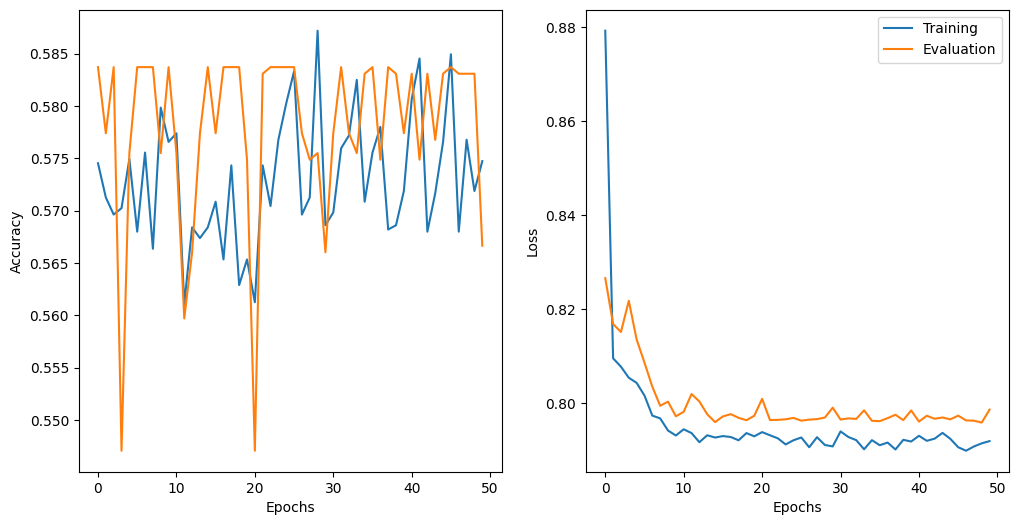

In [ ]:
plot_result(
    num_epochs,
    metrics["train_accuracy"],
    metrics["valid_accuracy"],
    metrics["train_loss"],
    metrics["valid_loss"]
)

plt.savefig("text_scratch_result.pdf")
plt.savefig("text_scratch_result.png")

##**7. Evaluation**

In [ ]:
train_acc, train_loss = evaluate_epoch(model, criterion, train_dataloader, device)
print(f"Train Set      - Accuracy: {train_acc:.4f}, Loss: {train_loss:.4f}")

valid_acc, valid_loss = evaluate_epoch(model, criterion, valid_dataloader, device)
print(f"Validation Set - Accuracy: {valid_acc:.4f}, Loss: {valid_loss:.4f}")

test_acc, test_loss = evaluate_epoch(model, criterion, test_dataloader, device)
print(f"Test Set       - Accuracy: {test_acc:.4f}, Loss: {test_loss:.4f}")

Train Set      - Accuracy: 0.5691, Loss: 0.7913
Validation Set - Accuracy: 0.5666, Loss: 0.7986
Test Set       - Accuracy: 0.5777, Loss: 0.8208


In [ ]:
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for inputs, labels in test_dataloader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        _, predicted = torch.max(outputs, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

label_names = ["Negative", "Neutral", "Positive"]
print(classification_report(all_labels, all_preds, target_names=label_names))

              precision    recall  f1-score   support

    Negative       0.58      0.51      0.54      1409
     Neutral       0.00      0.00      0.00       167
    Positive       0.58      0.70      0.63      1590

    accuracy                           0.58      3166
   macro avg       0.39      0.40      0.39      3166
weighted avg       0.55      0.58      0.56      3166



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
